# 08 - Figures 1-3 and Table 1

Fig 1 mouse atlas, Fig 2 HLiCA (authors' colour palette), Fig 3 SAMap (unintegrated row first), Table 1 SAMap matches
(kableExtra). Nature format: 183 x 170 mm, Arial 5-7 pt, audited with check_nature_fonts.py. The SAMap result itself comes from
heavy notebook 09 (record linked). The unintegrated UMAP is recomputed on GPU and may differ in layout from the record.

**Runtime:** ~15 min
**Envs used (each step runs as a subprocess in its own env):** rapids-sc (figure data), samap (figures), masld_tables (R kableExtra), latex (tectonic), masld_atlas (audit)
**Kernel:** `masld_atlas` (orchestration only).

Outputs are written under `/mnt/masld_vault/cross_species_repro/` (mirror of `/mnt/masld_vault/cross_species/`, the outputs
of record). Inputs this notebook does not rebuild are linked from the record; see `repro_setup.py` for the safety rules.

In [1]:
%run -i /home/ubuntu/liver_cross_species/notebooks/repro_setup.py
print("RECORD", RECORD); print("REPRO ", REPRO); print("WORK  ", WORK)

RECORD /mnt/masld_vault/cross_species
REPRO  /mnt/masld_vault/cross_species_repro
WORK   /home/ubuntu/liver_cross_species/notebooks/work


In [2]:
link("guilliams2022/13_annotation_of_record", "samap_run/input", "samap_run/out",
     "samap_maps/liver_hsmm/refs/orthologs/HOM_MouseHumanSequence.rpt")
fresh("figures", "figures/data", "figures/tables")

rebuilt   guilliams2022/13_annotation_of_record
rebuilt   samap_run/input
linked    samap_run/out
linked    samap_maps/liver_hsmm/refs/orthologs/HOM_MouseHumanSequence.rpt
output    figures
output    figures/data
output    figures/tables


### Shared figure settings (palettes, lineage maps, mm layout helpers)

In [3]:
%%writefile /home/ubuntu/liver_cross_species/notebooks/work/common.py
"""Shared figure settings (Nature spec: 183 mm wide, <= 170 mm tall, Arial 5-7 pt, panel letters 8 pt bold, TrueType text,
points rasterised at 450 dpi, Wong palette) + lineage maps for mouse (annotation_aor) and HLiCA (author_cell_type)."""
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import to_rgb
plt.rcParams.update({"font.family": "Arial", "font.size": 6, "pdf.fonttype": 42, "ps.fonttype": 42, "axes.linewidth": 0.5,
                     "xtick.major.width": 0.5, "ytick.major.width": 0.5, "xtick.major.size": 2, "ytick.major.size": 2,
                     "axes.titlesize": 6, "axes.labelsize": 6, "xtick.labelsize": 5, "ytick.labelsize": 5, "legend.fontsize": 5,
                     "axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 450})
MM = 1 / 25.4
D = "/mnt/masld_vault/cross_species_repro/figures"
WONG = {"Hepatocyte": "#E69F00", "Cholangiocyte": "#000000", "Endothelial": "#0072B2", "Mesenchymal": "#009E73",
        "Myeloid": "#D55E00", "DC": "#CC79A7", "B/plasma": "#F0E442", "T/NK/ILC": "#56B4E9", "Other": "#BBBBBB"}
LIN_ORDER = list(WONG)
MOUSE_LIN = {"Hepatocyte": "Hepatocyte", "Cholangiocyte": "Cholangiocyte", "Endothelial": "Endothelial", "Fibroblast": "Mesenchymal",
             "Mesothelial": "Mesenchymal", "KC": "Myeloid", "Monocyte": "Myeloid", "Neutrophil": "Myeloid", "Basophil": "Myeloid",
             "cDC1": "DC", "cDC2": "DC", "Mig. cDCs": "DC", "Transitional DC": "DC", "pDCs": "DC", "B cell": "B/plasma",
             "T cell": "T/NK/ILC", "NK cell": "T/NK/ILC", "ILC1": "T/NK/ILC", "unresolved": "Other"}
MOUSE_ORDER = list(MOUSE_LIN)
HUMAN_LIN = {**{k: "Hepatocyte" for k in ["Periportal Hepatocyte", "Pericentral Hepatocyte", "SERPINE1+ Hepatocyte", "UGT+ Hepatocyte",
                                          "Mito+ Hepatocyte", "Ribosomal+ Hepatocyte"]},
             **{k: "Cholangiocyte" for k in ["LAMC2+ Cholangiocyte", "ApoLipo", "Keratin", "CXCL8+ Keratin", "Mucus Secreting"]},
             **{k: "Endothelial" for k in ["Periportal LSEC", "LSEC", "Central Venous LSEC", "Portal Vein", "Hepatic Artery",
                                           "Vascular Endothelial Cell", "Lymphatic"]},
             **{k: "Mesenchymal" for k in ["Portal Fibroblast", "Hepatic Stellate Cell", "CUX2+ Hepatic Stellate Cell",
                                           "Vascular Smooth Muscle Cell", "NRXN1+ Stromal Cell"]},
             **{k: "Myeloid" for k in ["Kupffer Cells", "TREM2+ Macrophages", "Classical Monocytes", "Non-classical Monocytes",
                                       "Activated Monocytes", "BAG3+ Monocytes", "MAMLD1+ Trans Monocytes", "Neutrophils"]},
             **{k: "DC" for k in ["Type 1 cDCs", "Type 2 cDCs", "DCmac", "migDCs", "pDC"]},
             **{k: "B/plasma" for k in ["B Cell", "IgA B cells", "IgG B cells", "Plasma B Cell"]},
             **{k: "T/NK/ILC" for k in ["Helper T Cell", "Regulatory T Cell", "CD8 T Cell", "Exhausted CD8 T Cell", "MAIT T Cell",
                                        "Bright NK Cell", "Dim NK Cell"]},
             "Cycling": "Other"}
HUMAN_ORDER = list(HUMAN_LIN)


def shades(order, lin):
    """Per-type colours: the lineage's Wong colour, shaded light->dark within the lineage."""
    out = {}
    for L in LIN_ORDER:
        ts = [t for t in order if lin[t] == L]
        base = np.array(to_rgb(WONG[L]))
        for i, t in enumerate(ts):
            f = 0 if len(ts) == 1 else (i / (len(ts) - 1) - 0.5) * 0.7  # -0.35..0.35
            c = base + (1 - base) * (-f) if f < 0 else base * (1 - f)
            if L == "Cholangiocyte":
                c = np.array([0.15 + 0.12 * i] * 3)
            out[t] = tuple(np.clip(c, 0, 1))
    return out


def ax_mm(fig, x, y, w, h, W=183, H=170):
    """axes from mm, origin top-left."""
    return fig.add_axes([x / W, 1 - (y + h) / H, w / W, h / H])


def letter(fig, x, y, s, W=183, H=170):
    fig.text(x / W, 1 - y / H, s, fontsize=8, fontweight="bold", va="top", ha="left")


def umap_ax(ax, U, colors, s=0.15, order=None):
    o = np.random.default_rng(0).permutation(len(U)) if order is None else order
    ax.scatter(U[o, 0], U[o, 1], c=np.asarray(colors, dtype=object)[o].tolist(), s=s, lw=0, rasterized=True)
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(False)
    # arrows a fixed 7 mm long whatever the panel size (user 2026-11-12: arrows too small in small panels)
    pos = ax.get_position(); fw, fh = ax.figure.get_size_inches()
    fx, fy = 7 / (pos.width * fw * 25.4), 7 / (pos.height * fh * 25.4)
    x0, y0 = U[:, 0].min(), U[:, 1].min(); dx, dy = np.ptp(U[:, 0]) * fx, np.ptp(U[:, 1]) * fy
    ax.annotate("", (x0 + dx, y0), (x0, y0), arrowprops=dict(arrowstyle="-|>", lw=0.5, color="k", mutation_scale=4))
    ax.annotate("", (x0, y0 + dy), (x0, y0), arrowprops=dict(arrowstyle="-|>", lw=0.5, color="k", mutation_scale=4))
    ax.text(x0, y0 - dy * 0.15, "UMAP1", fontsize=5, va="top"); ax.text(x0 - dx * 0.15, y0, "UMAP2", fontsize=5, rotation=90, ha="right")


# HLiCA authors' palette (github quon-titative-biology/HLiCA src/Annotations/Liver_Cell_Atlas/Analysis_03/colour_palette.R,
# myColors_celltype; names assigned positionally as in the R code, so LSEC / Vascular Endothelial Cell follow R, not the comments)
_HC = ["#994676", "#ce1256", "#d9667f", "#ce1256", "#b80783", "#b01629", "#d9667f", "#914e84", "#b01629", "#d9667f", "#d9667f", "#ce1256",
       "#FFA500", "#FF8C00", "#FFB347", "#FF7F50", "#FFAA33",
       "#8B4513", "#A0522D", "#CD853F", "#B5651D", "#DEB887", "#8B3E2F", "#A52A2A",
       "#F0E68C", "#FFD700", "#FFFACD", "#F5DEB3", "#f09d02", "#f09d02",
       "#663399", "#800080", "#9370DB", "#9851b0",
       "#006400", "#339500", "#4CAF00", "#66C700", "#b0db93", "#5f9c4e", "#4c9638",
       "#6495ED", "#1d91c0", "#74a9cf", "#9ecae1", "#0570b0", "#08519c", "#eb150c", "#000066"]
_HN = ["Kupffer Cells", "Classical Monocytes", "Type 2 cDCs", "Non-classical Monocytes", "TREM2+ Macrophages", "MAMLD1+ Trans Monocytes", "DCmac",
       "Neutrophils", "Activated Monocytes", "migDCs", "Type 1 cDCs", "BAG3+ Monocytes",
       "ApoLipo", "Keratin", "LAMC2+ Cholangiocyte", "CXCL8+ Keratin", "Mucus Secreting",
       "Periportal LSEC", "Portal Vein", "Central Venous LSEC", "Lymphatic", "Hepatic Artery", "Vascular Endothelial Cell", "LSEC",
       "Hepatic Stellate Cell", "Vascular Smooth Muscle Cell", "Portal Fibroblast", "CUX2+ Hepatic Stellate Cell", "NRXN1+ Hepatic Stellate Cell",
       "NRXN1+ Stromal Cell", "Plasma B Cell", "B Cell", "IgA B cells", "IgG B cells",
       "Bright NK Cell", "Dim NK Cell", "Helper T Cell", "CD8 T Cell", "MAIT T Cell", "Exhausted CD8 T Cell", "Regulatory T Cell",
       "Ribosomal+ Hepatocyte", "UGT+ Hepatocyte", "Mito+ Hepatocyte", "Pericentral Hepatocyte", "Periportal Hepatocyte", "SERPINE1+ Hepatocyte",
       "pDC", "Cycling"]
HLICA_COLORS = dict(zip(_HN, _HC))
# HLiCA lineages (myColors_celltype_alpha)
HLICA_LIN_COLORS = {"Hepatocyte": "#6495ED", "Cholangiocyte": "#FFA500", "Endothelia": "#CD853F", "Mesenchyme": "#FFD700",
                    "Myeloid Cell": "#ce1256", "Lymphocyte": "#339500", "pDC": "#eb150c", "Cycling": "#000066"}
HLICA_LIN = {}
for t in _HN:
    L = HUMAN_LIN.get(t)
    HLICA_LIN[t] = {"Hepatocyte": "Hepatocyte", "Cholangiocyte": "Cholangiocyte", "Endothelial": "Endothelia", "Mesenchymal": "Mesenchyme",
                    "Myeloid": "Myeloid Cell", "DC": "Myeloid Cell", "B/plasma": "Lymphocyte", "T/NK/ILC": "Lymphocyte"}.get(L, t)
HLICA_LIN["pDC"] = "pDC"; HLICA_LIN["Cycling"] = "Cycling"
HLICA_ORDER = [t for L in HLICA_LIN_COLORS for t in HUMAN_ORDER if HLICA_LIN.get(t) == L]

Overwriting /home/ubuntu/liver_cross_species/notebooks/work/common.py


### Figure data: unintegrated baseline, dot plot statistics

In [4]:
%%writefile /home/ubuntu/liver_cross_species/notebooks/work/fig_00_data.py
"""Figure data (2026-11-12): small tables so the figure scripts run in seconds.
1. Unintegrated baseline for Fig 2: same SAMap input cells (hs 50,400 + mm 53,370), genes = MGI 1:1 orthologs present in both
   (mouse symbol), counts concatenated, normalise_total 1e4 + log1p, 3,000 HVG (seurat, no batch key), PCA 50, kNN 15, UMAP seed 0 (rapids-singlecell, GPU).
2. Fig 1 dot plot statistics: mean log-normalised expression and fraction > 0 per annotation_aor type for the Table S1 top-3 genes.
3. Per-cell tables: mouse AoR UMAP + labels; SAMap joint UMAP + labels.
Outputs <D>/data/."""
import anndata as ad, numpy as np, pandas as pd, scanpy as sc, scipy.sparse as sp
import sys; sys.path.insert(0, "/home/ubuntu/liver_cross_species/notebooks/work")
from common import D
I = "/mnt/masld_vault/cross_species_repro/samap_run/input"
# 1 unintegrated
mgi = pd.read_csv("/mnt/masld_vault/cross_species_repro/samap_maps/liver_hsmm/refs/orthologs/HOM_MouseHumanSequence.rpt", sep="\t", dtype=str)
one = mgi.groupby("DB Class Key").filter(lambda x: (x["NCBI Taxon ID"] == "10090").sum() == 1 and (x["NCBI Taxon ID"] == "9606").sum() == 1)
p = one.pivot_table(index="DB Class Key", columns="NCBI Taxon ID", values="Symbol", aggfunc="first").rename(columns={"9606": "hs", "10090": "mm"})
h = ad.read_h5ad(f"{I}/hs_samap_ready.h5ad"); m = ad.read_h5ad(f"{I}/mm_samap_ready.h5ad")
p = p[p.hs.isin(h.var_names) & p.mm.isin(m.var_names)]
print("1:1 orthologs in both objects:", len(p), flush=True)
hh = h[:, p.hs.values].copy(); hh.var_names = p.mm.values
mm_ = m[:, p.mm.values].copy()
hh.obs = pd.DataFrame({"species": "human", "label": h.obs.author_cell_type.astype(str).values}, index="hs_" + h.obs_names)
mm_.obs = pd.DataFrame({"species": "mouse", "label": m.obs.annotation_aor.astype(str).values}, index="mm_" + m.obs_names)
u = ad.concat([hh, mm_]); u.X = sp.csr_matrix(u.X)
sc.pp.normalize_total(u, target_sum=1e4); sc.pp.log1p(u)
sc.pp.highly_variable_genes(u, n_top_genes=3000, flavor="seurat")
sc.pp.pca(u, n_comps=50, mask_var="highly_variable", random_state=0)
import rapids_singlecell as rsc; rsc.pp.neighbors(u, n_neighbors=15, use_rep="X_pca"); rsc.tl.umap(u, random_state=0)
pd.DataFrame({"species": u.obs.species.values, "label": u.obs.label.values, "u1": u.obsm["X_umap"][:, 0], "u2": u.obsm["X_umap"][:, 1]},
             index=u.obs_names).to_parquet(f"{D}/data/unintegrated_umap.parquet")
print("unintegrated done", flush=True)
del u, hh, mm_, h, m
# 3a SAMap joint
j = ad.read_h5ad("/mnt/masld_vault/cross_species_repro/samap_run/out/samap_joint.h5ad", backed="r")
sp_ = j.obs.species.astype(str).values
lab = np.where(sp_ == "hs", j.obs.hs_author_cell_type.astype(str).values, j.obs.mm_annotation_aor.astype(str).values)
pd.DataFrame({"species": np.where(sp_ == "hs", "human", "mouse"), "label": lab, "u1": j.obsm["X_umap"][:, 0], "u2": j.obsm["X_umap"][:, 1]},
             index=j.obs_names).to_parquet(f"{D}/data/samap_umap.parquet")
# 2 + 3b mouse
a = ad.read_h5ad("/mnt/masld_vault/cross_species_repro/guilliams2022/13_annotation_of_record/guilliams2022_fig1b_aor.h5ad")
pd.DataFrame({"label": a.obs.annotation_aor.astype(str).values, "suspension": a.obs.suspension.astype(str).values,
              "digestion": a.obs.digestion.astype(str).values, "u1": a.obsm["X_umap"][:, 0], "u2": a.obsm["X_umap"][:, 1]},
             index=a.obs_names).to_parquet(f"{D}/data/mouse_aor_umap.parquet")
sc.pp.normalize_total(a, target_sum=1e4); sc.pp.log1p(a)
a.var_names = a.var.symbol.astype(str).values; a.var_names_make_unique()
S1 = "/mnt/masld_vault/geo/GSE192740/paper_supplement_cell2022/1-s2.0-S0092867421014811-mmc1.xlsx"
x = pd.read_excel(S1, sheet_name=None); genes = {}
for k, v in x.items():
    if k.startswith("Mouse") and k.endswith("DEGs"):
        genes[k.replace("Mouse ", "").replace(" DEGs", "")] = [g for g in v.sort_values("score", ascending=False).iloc[:, 0].astype(str) if g in a.var_names][:3]
genes["Transitional DC"] = ["Ly6c2", "Cd209a", "Siglech"]; genes["Mesothelial"] = ["Msln", "Upk3b", "Lrrn4"]
pd.Series({k: ",".join(v) for k, v in genes.items()}).to_csv(f"{D}/data/dotplot_genes.tsv", sep="\t", header=False)
gl = list(dict.fromkeys(g for v in genes.values() for g in v))
lab = a.obs.annotation_aor.astype(str).values
X = a[:, gl].X; X = X.toarray() if sp.issparse(X) else X
mean = pd.DataFrame(X, columns=gl).groupby(lab).mean(); frac = pd.DataFrame(X > 0, columns=gl).groupby(lab).mean()
mean.to_csv(f"{D}/data/dotplot_mean.tsv", sep="\t"); frac.to_csv(f"{D}/data/dotplot_frac.tsv", sep="\t")
print("done", flush=True)

Overwriting /home/ubuntu/liver_cross_species/notebooks/work/fig_00_data.py


In [5]:
run("fig_00_data.py", "rapids-sc", gpu=0)

1:1 orthologs in both objects: 15340
  hh = h[:, p.hs.values].copy(); hh.var_names = p.mm.values
unintegrated done
done
--- fig_00_data.py [rapids-sc] exit 0, 1.4 min, log /home/ubuntu/liver_cross_species/notebooks/work/logs/fig_00_data.py.log


### HLiCA figure data

In [6]:
%%writefile /home/ubuntu/liver_cross_species/notebooks/work/fig_00b_hlica_data.py
"""HLiCA figure data (2026-11-12): per-cell UMAP (deposited X_umap) + labels for all 524,699 cells; lineage dot plot statistics
(HLiCA canonical lineage markers, Zenodo 20380927) on the SAMap subsample (50,400 cells, <= 1,200 per author_cell_type, raw counts ->
normalise_total 1e4 + log1p), grouped by HLiCA lineage (colour_palette.R alpha). Outputs <D>/data/hlica_*."""
import sys; sys.path.insert(0, "/home/ubuntu/liver_cross_species/notebooks/work")
import anndata as ad, numpy as np, pandas as pd, scanpy as sc, scipy.sparse as sp
from common import D, HLICA_LIN
h = ad.read_h5ad("/mnt/masld_vault/geo/cxg-059202e1-1f1b-483f-9151-f3a25a380c39/HLiCA_human_liver_all_cells.h5ad", backed="r")
o = h.obs
pd.DataFrame({"label": o.author_cell_type.astype(str).values, "suspension": o.suspension_type.astype(str).values, "study": o.STUDY.astype(str).values,
              "donor": o.donor_id.astype(str).values, "u1": h.obsm["X_umap"][:, 0], "u2": h.obsm["X_umap"][:, 1]}, index=o.index).to_parquet(f"{D}/data/hlica_umap.parquet")
mk = pd.read_csv("/mnt/masld_vault/geo/zenodo-20380927/HLiCA_lineage_markers.csv")
print(mk.groupby(["Lineage", "Marker Type"]).Gene.apply(list).to_string())
s = ad.read_h5ad("/mnt/masld_vault/cross_species_repro/samap_run/input/hs_samap_ready.h5ad")
sc.pp.normalize_total(s, target_sum=1e4); sc.pp.log1p(s)
genes = [g for g in mk.Gene if g in s.var_names]
lin = s.obs.author_cell_type.astype(str).map(HLICA_LIN).values
X = s[:, genes].X; X = X.toarray() if sp.issparse(X) else X
pd.DataFrame(X, columns=genes).groupby(lin).mean().to_csv(f"{D}/data/hlica_dot_mean.tsv", sep="\t")
pd.DataFrame(X > 0, columns=genes).groupby(lin).mean().to_csv(f"{D}/data/hlica_dot_frac.tsv", sep="\t")
mk[mk.Gene.isin(genes)].to_csv(f"{D}/data/hlica_dot_genes.tsv", sep="\t", index=False)
print("done")

Overwriting /home/ubuntu/liver_cross_species/notebooks/work/fig_00b_hlica_data.py


In [7]:
run("fig_00b_hlica_data.py", "samap")

Lineage        Marker Type
Cholangiocyte  Canonical                                   [EPCAM, CD24, KRT19]
Endothelia     Canonical      [CD34, STAB1, KDR, ICAM2, CLEC4G, ENG, ERG, CD...
Hepatocytes    Additional                           [ASGR1, ASS1, PCK1, MFSD2A]
               Canonical                      [CYP2A6, HNF4A, HP, TF, TTR, ALB]
Lymphocytes    Additional                                     [ILR7, CD7, CTSW]
               Canonical      [CD4, CD8A, CD3G, CD3E, CD3D, MS4A1, CD19, CD7...
Mesenchyme     Additional                                 [COLEC11, HGF, PTH1R]
               Canonical      [DCN, DES, COL3A1, COL1A2, COL1A1, ACTA2, PDGF...
Myeloid        Additional                      [CD163, LILRB5, LYZ, AIF1, LST1]
               Canonical      [CD14, CSF1R, HLA-DRA, ITGAX, ITGAM, CD68, FCG...
done
--- fig_00b_hlica_data.py [samap] exit 0, 0.2 min, log /home/ubuntu/liver_cross_species/notebooks/work/logs/fig_00b_hlica_data.py.log


### Figure 1 - mouse atlas

In [8]:
%%writefile /home/ubuntu/liver_cross_species/notebooks/work/fig1_mouse_atlas.py
"""Figure 1 - Guilliams 2022 mouse liver atlas rebuilt from GEO (183 x 170 mm, Nature spec).
a UMAP annotation of record (TotalVI, strict QC); b suspension; c digestion; d cells kept per QC step (paper: 185,894);
e composition by type and suspension; f Table S1 top-3 markers per type (dot plot, mean log CP10k scaled per gene).
Inputs <D>/data (fig_00_data.py). Outputs <D>/fig1_mouse_atlas.{pdf,png}."""
import sys; sys.path.insert(0, "/home/ubuntu/liver_cross_species/notebooks/work")
import numpy as np, pandas as pd
from common import plt, MM, D, MOUSE_ORDER, MOUSE_LIN, shades, ax_mm, letter, umap_ax
from matplotlib.lines import Line2D
u = pd.read_parquet(f"{D}/data/mouse_aor_umap.parquet"); U = u[["u1", "u2"]].values
order = [t for t in MOUSE_ORDER if t in set(u.label)]
col = shades([t for t in order if t != "unresolved"], MOUSE_LIN); col["unresolved"] = (0.8, 0.8, 0.8)
fig = plt.figure(figsize=(183 * MM, 170 * MM))
# a
ax = ax_mm(fig, 4, 4, 68, 56); umap_ax(ax, U, [col[l] for l in u.label], s=0.08)
ax.set_title(f"Mouse liver, rebuilt: {len(u):,} cells and nuclei", pad=2)
n = u.label.value_counts()
lg = ax_mm(fig, 79, 4, 34, 56); lg.axis("off")
lg.legend([Line2D([], [], ls="", marker="o", ms=3, mfc=col[t], mec="none") for t in order], [f"{t} ({n[t]:,})" for t in order],
          loc="upper left", frameon=False, handletextpad=0.2, labelspacing=0.25, borderaxespad=0, title="Cell type (n)", title_fontsize=5,
          alignment="left")
letter(fig, 1, 2, "a")
# b, c
SUS = {"cell": "#56B4E9", "nucleus": "#D55E00"}; DIG = {"Ex Vivo": "#009E73", "In Vivo": "#CC79A7", "Nuclei": "#000000"}
for (y, key, pal, ttl, L) in ((4, "suspension", SUS, "Suspension", "b"), (33, "digestion", DIG, "Digestion", "c")):
    ax = ax_mm(fig, 120, y, 27, 26); umap_ax(ax, U, [pal[v] for v in u[key]], s=0.04); ax.set_title(ttl, pad=1)
    lg = ax_mm(fig, 152, y + 6, 29, 16); lg.axis("off")
    vc = u[key].value_counts()
    lg.legend([Line2D([], [], ls="", marker="o", ms=3, mfc=pal[k], mec="none") for k in pal], [f"{k} ({vc.get(k, 0):,})" for k in pal],
              loc="upper left", frameon=False, handletextpad=0.2, borderaxespad=0)
    letter(fig, 116, y - 2, L)
# d QC flow
# counts read from the step outputs (review 2026-11-12: no typed-in numbers); strict removals in the order reasons were assigned
G = "/mnt/masld_vault/cross_species_repro/guilliams2022"
st = pd.read_csv(f"{G}/01_raw/sample_table.tsv", sep="\t")
n_raw, n_qc = int(st.n_cells_file.sum()), int(pd.read_csv(f"{G}/06_doublets_ambient/per_sample_summary.tsv", sep="\t").n_kept.sum())
rr = pd.read_parquet(f"{G}/10_strict/cells_strict.parquet", columns=["strict_remove_reason"]).strict_remove_reason.astype(str).value_counts()
n = int(rr.sum()); steps = [(f"Fig 1B samples on GEO ({len(st)})", n_raw), ("Authors' MAD QC + Scrublet", n_qc), ("Doublet clusters removed", n)]
for r, lab in (("scDblFinder_doublet", "scDblFinder doublets"), ("dx_lt200", "< 200 UMI after decontX"), ("bridge", "Between-type (bridge) cells"),
               ("sort_mismatch", "Sort-gate mismatches (final)")):
    n -= int(rr.get(r, 0)); steps.append((lab, n))
assert n == int(rr["kept"]) == len(u), (n, rr["kept"], len(u))
ax = ax_mm(fig, 42, 67, 52, 38)
y = np.arange(len(steps))[::-1]
ax.barh(y, [v / 1e3 for _, v in steps], color=["#BBBBBB"] * 6 + ["#000000"], height=0.65)
for yi, (_, v) in zip(y, steps): ax.text(v / 1e3 + 4, yi, f"{v:,}", va="center", fontsize=5)
ax.axvline(185.894, ls="--", lw=0.5, color="#D55E00"); ax.text(185.894, len(steps) - 0.35, "paper 185,894", color="k", fontsize=5, ha="center")
ax.set_yticks(y, [s for s, _ in steps]); ax.set_xlabel("Cells and nuclei kept (thousands)"); ax.set_xlim(0, 470)
letter(fig, 1, 63, "d")
# e composition
comp = pd.crosstab(u.label, u.suspension).reindex(order)
ax = ax_mm(fig, 124, 67, 52, 38)
yy = np.arange(len(order))[::-1]
ax.barh(yy, comp["cell"] / 1e3, color=SUS["cell"], height=0.7, label="cell")
ax.barh(yy, comp["nucleus"] / 1e3, left=comp["cell"] / 1e3, color=SUS["nucleus"], height=0.7, label="nucleus")
ax.set_yticks(yy, order, fontsize=5); ax.tick_params(axis="y", length=0, pad=1); ax.set_xlabel("Cells and nuclei (thousands)")
ax.legend(frameon=False, loc="lower right", handlelength=1)
letter(fig, 101, 63, "e")
# f dot plot
genes = pd.read_csv(f"{D}/data/dotplot_genes.tsv", sep="\t", header=None, index_col=0)[1].str.split(",")
mean = pd.read_csv(f"{D}/data/dotplot_mean.tsv", sep="\t", index_col=0); frac = pd.read_csv(f"{D}/data/dotplot_frac.tsv", sep="\t", index_col=0)
rows = [t for t in order if t != "unresolved"]
gl = list(dict.fromkeys(g for t in rows for g in genes[t]))
M = mean.loc[rows, gl]; M = (M - M.min()) / (M.max() - M.min()); F = frac.loc[rows, gl]
ax = ax_mm(fig, 22, 117, 140, 33)
xi, yi = np.meshgrid(np.arange(len(gl)), np.arange(len(rows))[::-1])
sc_ = ax.scatter(xi.ravel(), yi.ravel(), s=(F.values.ravel() * 9), c=M.values.ravel(), cmap="Reds", vmin=0, vmax=1, lw=0)
ax.set_xticks(range(len(gl)), gl, rotation=90, fontsize=5, style="italic"); ax.set_yticks(range(len(rows))[::-1], rows, fontsize=5)
ax.set_xlim(-0.7, len(gl) - 0.3); ax.set_ylim(-0.7, len(rows) - 0.3); ax.tick_params(length=0, pad=1)
for sp in ax.spines.values(): sp.set_visible(False)
ax.set_title("Table S1 top-3 marker genes per type (Guilliams et al. 2022)", pad=2)
cax = ax_mm(fig, 166, 119, 2, 12); cb = fig.colorbar(sc_, cax=cax); cb.set_label("Scaled mean", fontsize=5); cb.ax.tick_params(labelsize=5, width=0.5, length=1.5); cb.outline.set_linewidth(0.5)
lg = ax_mm(fig, 164, 135, 17, 14); lg.axis("off")
lg.legend([plt.scatter([], [], s=f * 9, c="k", lw=0) for f in (0.25, 0.5, 1.0)], ["25", "50", "100"], title="% expressing", title_fontsize=5,
          frameon=False, loc="upper left", handletextpad=0.2, labelspacing=0.3, borderaxespad=0)
letter(fig, 1, 112, "f")
fig.savefig(f"{D}/fig1_mouse_atlas.pdf"); fig.savefig(f"{D}/fig1_mouse_atlas.png", dpi=300)
print("written")

Overwriting /home/ubuntu/liver_cross_species/notebooks/work/fig1_mouse_atlas.py


In [9]:
run("fig1_mouse_atlas.py", "samap")

written
--- fig1_mouse_atlas.py [samap] exit 0, 0.2 min, log /home/ubuntu/liver_cross_species/notebooks/work/logs/fig1_mouse_atlas.py.log


### Figure 2 - HLiCA

In [10]:
%%writefile /home/ubuntu/liver_cross_species/notebooks/work/fig2_hlica.py
"""Figure 2 - Human Liver Cell Atlas (HLiCA v1.0, CELLxGENE; Edgar, Portman et al. 2026) as used for SAMap (183 x 170 mm).
a deposited UMAP, 48 author_cell_type labels in the HLiCA authors' colours (colour_palette.R); b suspension; c study; d cells per study by suspension;
e HLiCA lineage composition per study (authors' lineage colours); f HLiCA canonical lineage markers (Zenodo 20380927) on the SAMap subsample (50,400 cells).
Outputs <D>/fig2_hlica.{pdf,png}."""
import sys; sys.path.insert(0, "/home/ubuntu/liver_cross_species/notebooks/work")
import numpy as np, pandas as pd
from matplotlib.lines import Line2D
from common import plt, MM, D, HLICA_COLORS, HLICA_LIN, HLICA_LIN_COLORS, HLICA_ORDER, ax_mm, letter, umap_ax
u = pd.read_parquet(f"{D}/data/hlica_umap.parquet"); U = u[["u1", "u2"]].values
u["lineage"] = u.label.map(HLICA_LIN)
col = HLICA_COLORS
fig = plt.figure(figsize=(183 * MM, 170 * MM))
ax = ax_mm(fig, 4, 5, 64, 64); umap_ax(ax, U, [col[l] for l in u.label], s=0.03)
ax.set_title(f"HLiCA v1.0: {len(u):,} cells and nuclei, {u.donor.nunique()} donors, {u.study.nunique()} studies", pad=2, loc="left")
for j, chunk in enumerate((HLICA_ORDER[:24], HLICA_ORDER[24:])):
    lg = ax_mm(fig, 70 + j * 31, 7, 30, 62); lg.axis("off")
    lg.legend([Line2D([], [], ls="", marker="o", ms=2.6, mfc=col[t], mec="none") for t in chunk], chunk, loc="upper left", frameon=False,
              handletextpad=0.1, labelspacing=0.28, borderaxespad=0, title="Cell type (author)" if j == 0 else " ", title_fontsize=5, alignment="left")
letter(fig, 1, 3, "a")
SUS = {"cell": "#56B4E9", "nucleus": "#D55E00"}
studies = u.study.value_counts().index.tolist()
STU = dict(zip(studies, ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7", "#000000"]))
ax = ax_mm(fig, 136, 5, 26, 26); umap_ax(ax, U, [SUS[v] for v in u.suspension], s=0.02); ax.set_title("Suspension", pad=1)
lg = ax_mm(fig, 163, 12, 20, 10); lg.axis("off"); vc = u.suspension.value_counts()
lg.legend([Line2D([], [], ls="", marker="o", ms=3, mfc=SUS[k], mec="none") for k in SUS], [f"{k}\n({vc[k]:,})" for k in SUS], frameon=False,
          loc="upper left", handletextpad=0.2, borderaxespad=0, labelspacing=0.4)
letter(fig, 133, 3, "b")
ax = ax_mm(fig, 136, 37, 26, 26); umap_ax(ax, U, [STU[v] for v in u.study], s=0.02); ax.set_title("Study", pad=1)
lg = ax_mm(fig, 136, 65, 47, 10); lg.axis("off")
lg.legend([Line2D([], [], ls="", marker="o", ms=3, mfc=STU[k], mec="none") for k in studies], [k.replace("_", " ") for k in studies], frameon=False,
          loc="upper left", ncol=2, handletextpad=0.2, borderaxespad=0, columnspacing=0.6, labelspacing=0.25)
letter(fig, 133, 35, "c")
# d cells per study by suspension
ct = pd.crosstab(u.study, u.suspension).reindex(studies)
ax = ax_mm(fig, 30, 86, 50, 30); y = np.arange(len(studies))[::-1]
ax.barh(y, ct["cell"] / 1e3, color=SUS["cell"], height=0.7); ax.barh(y, ct["nucleus"] / 1e3, left=ct["cell"] / 1e3, color=SUS["nucleus"], height=0.7)
ax.set_yticks(y, [s.replace("_", " ") for s in studies]); ax.tick_params(axis="y", length=0, pad=1)
ax.set_xlabel("Cells and nuclei (thousands)")
dn = u.groupby("study").donor.nunique()
for yi, s in zip(y, studies): ax.text(ct.loc[s].sum() / 1e3 + 2, yi, f"{dn[s]} donors", va="center", fontsize=5)
ax.set_xlim(0, 175)
letter(fig, 1, 83, "d")
# e lineage composition per study
lc = pd.crosstab(u.study, u.lineage, normalize="index").reindex(studies)[[l for l in HLICA_LIN_COLORS if l in set(u.lineage)]]
ax = ax_mm(fig, 116, 86, 46, 30); left = np.zeros(len(studies))
for L in lc.columns:
    ax.barh(y, lc[L].values * 100, left=left, color=HLICA_LIN_COLORS[L], height=0.7, label=L); left += lc[L].values * 100
ax.set_yticks(y, [s.replace("_", " ") for s in studies]); ax.tick_params(axis="y", length=0, pad=1); ax.set_xlim(0, 100)
ax.set_xlabel("Share of study (%)")
lg = ax_mm(fig, 164, 86, 19, 30); lg.axis("off")
lg.legend([Line2D([], [], ls="", marker="s", ms=3, mfc=HLICA_LIN_COLORS[k], mec="none") for k in lc.columns], list(lc.columns), frameon=False, loc="upper left",
          handletextpad=0.2, borderaxespad=0, labelspacing=0.3, title="Lineage", title_fontsize=5, alignment="left")
letter(fig, 87, 83, "e")
# f lineage dot plot
mk = pd.read_csv(f"{D}/data/hlica_dot_genes.tsv", sep="\t"); mk = mk[mk["Marker Type"] == "Canonical"]
LORD = ["Hepatocytes", "Cholangiocyte", "Endothelia", "Mesenchyme", "Myeloid", "Lymphocytes"]
gl = []
for L in LORD: gl += mk[mk.Lineage == L].Gene.tolist()[:5] if L != "Lymphocytes" else [g for g in ["CD3E", "CD8A", "NKG7", "KLRF1", "MS4A1", "CD79A", "JCHAIN"] if g in mk.Gene.values]
mean = pd.read_csv(f"{D}/data/hlica_dot_mean.tsv", sep="\t", index_col=0); frac = pd.read_csv(f"{D}/data/hlica_dot_frac.tsv", sep="\t", index_col=0)
rows = [l for l in HLICA_LIN_COLORS if l in mean.index]
Mm = mean.loc[rows, gl]; Mm = (Mm - Mm.min()) / (Mm.max() - Mm.min()); F = frac.loc[rows, gl]
ax = ax_mm(fig, 26, 132, 120, 20)
xi, yi = np.meshgrid(np.arange(len(gl)), np.arange(len(rows))[::-1])
s_ = ax.scatter(xi.ravel(), yi.ravel(), s=F.values.ravel() * 9, c=Mm.values.ravel(), cmap="Reds", vmin=0, vmax=1, lw=0)
ax.set_xticks(range(len(gl)), gl, rotation=90, style="italic"); ax.set_yticks(range(len(rows))[::-1], rows)
ax.set_xlim(-0.7, len(gl) - 0.3); ax.set_ylim(-0.7, len(rows) - 0.3); ax.tick_params(length=0, pad=1)
for sp in ax.spines.values(): sp.set_visible(False)
xb = 0
for L in LORD:
    nL = sum(g in mk[mk.Lineage == L].Gene.values for g in gl)
    ax.text(xb + nL / 2 - 0.5, len(rows) - 0.1, {"Hepatocytes": "Hepatocyte", "Myeloid": "Myeloid Cell", "Lymphocytes": "Lymphocyte"}.get(L, L), ha="center", va="bottom", fontsize=5)
    ax.plot([xb - 0.4, xb + nL - 0.6], [len(rows) - 0.25] * 2, color="k", lw=0.5, clip_on=False); xb += nL
ax.set_title("HLiCA canonical lineage markers (SAMap subsample, 50,400 cells)", pad=9)
cax = ax_mm(fig, 152, 132, 2, 11); cb = fig.colorbar(s_, cax=cax); cb.set_label("Scaled mean", fontsize=5)
cb.ax.tick_params(labelsize=5, width=0.5, length=1.5); cb.outline.set_linewidth(0.5)
lg = ax_mm(fig, 164, 130, 18, 14); lg.axis("off")
lg.legend([plt.scatter([], [], s=f * 9, c="k", lw=0) for f in (0.25, 0.5, 1.0)], ["25", "50", "100"], title="% expressing", title_fontsize=5,
          frameon=False, loc="upper left", handletextpad=0.2, labelspacing=0.3, borderaxespad=0)
letter(fig, 1, 124, "f")
fig.savefig(f"{D}/fig2_hlica.pdf"); fig.savefig(f"{D}/fig2_hlica.png", dpi=300)
print("written")

Overwriting /home/ubuntu/liver_cross_species/notebooks/work/fig2_hlica.py


In [11]:
run("fig2_hlica.py", "samap")

written
--- fig2_hlica.py [samap] exit 0, 0.4 min, log /home/ubuntu/liver_cross_species/notebooks/work/logs/fig2_hlica.py.log


### Figure 3 - SAMap

In [12]:
%%writefile /home/ubuntu/liver_cross_species/notebooks/work/fig3_samap.py
"""Figure 3 - SAMap human (HLiCA v1.0) x mouse (Guilliams 2022, rebuilt) liver (183 x 170 mm, Nature spec).
a,b unintegrated baseline (same cells, MGI 1:1 orthologs, normalise + log1p, 3,000 HVG, PCA 50, UMAP; fig_00_data.py) by species / lineage;
c,d SAMap joint UMAP (sc-samap 3.0.1) by species / lineage; e best matches mouse type -> HLiCA type (mapping score >= 0.4, width = score);
f mapping scores for all mouse x HLiCA types (lineage bars on the margins).
Note: HLiCA contains the Guilliams 2022 human samples (51,554 cells); the mouse atlas is the same lab's mouse data.
Layout rule (2026-11-12 user): no overlapping text - every label block has its own reserved mm band.
Gene pairs behind each match: separate Table 1 (tab1_data.py + tab1_kable.R; user 2026-11-12, panel removed, a-d enlarged).
Outputs <D>/fig3_samap.{pdf,png}."""
import sys; sys.path.insert(0, "/home/ubuntu/liver_cross_species/notebooks/work")
import numpy as np, pandas as pd
from matplotlib.path import Path
from matplotlib.patches import PathPatch
from matplotlib.lines import Line2D
from common import plt, MM, D, WONG, LIN_ORDER, MOUSE_LIN, HUMAN_LIN, MOUSE_ORDER, HUMAN_ORDER, ax_mm, letter, umap_ax
O = "/mnt/masld_vault/cross_species_repro/samap_run/out"
SPC = {"human": "#D55E00", "mouse": "#0072B2"}
def lin_of(sp, l): return (HUMAN_LIN if sp == "human" else MOUSE_LIN).get(l, "Other")
fig = plt.figure(figsize=(183 * MM, 170 * MM))
# a-d: 2 x 2 UMAPs, unintegrated row first (y 5-38), SAMap row (y 45-78)
for i, (f, ttl) in enumerate((("unintegrated_umap", "Unintegrated"), ("samap_umap", "SAMap"))):
    u = pd.read_parquet(f"{D}/data/{f}.parquet"); U = u[["u1", "u2"]].values
    y = 7 + i * 49
    ax = ax_mm(fig, 5, y, 42, 42); umap_ax(ax, U, [SPC[s] for s in u.species], s=0.05); ax.set_title(f"{ttl}: species", pad=1)
    ax = ax_mm(fig, 50, y, 42, 42); umap_ax(ax, U, [WONG[lin_of(s, l)] for s, l in zip(u.species, u.label)], s=0.05)
    ax.set_title(f"{ttl}: lineage", pad=1)
    letter(fig, 1, y - 4, "ac"[i]); letter(fig, 46, y - 4, "bd"[i])
n = pd.read_parquet(f"{D}/data/samap_umap.parquet").species.value_counts()
lg = ax_mm(fig, 93, 10, 14, 10); lg.axis("off")
lg.legend([Line2D([], [], ls="", marker="o", ms=3, mfc=SPC[k], mec="none") for k in SPC], [f"{k}\n({n[k]:,})" for k in SPC], title="Species",
          title_fontsize=5, frameon=False, loc="upper left", handletextpad=0.2, borderaxespad=0, labelspacing=0.5, alignment="left")
lg = ax_mm(fig, 93, 34, 14, 30); lg.axis("off")
lg.legend([Line2D([], [], ls="", marker="o", ms=3, mfc=WONG[k], mec="none") for k in LIN_ORDER], LIN_ORDER, title="Lineage", title_fontsize=5,
          frameon=False, loc="upper left", handletextpad=0.2, borderaxespad=0, labelspacing=0.3, alignment="left")
# mapping table
M = pd.read_csv(f"{O}/mapping_table.tsv", sep="\t", index_col=0)
mrows = [t for t in MOUSE_ORDER if "mm_" + t in M.index]; hcols = [t for t in HUMAN_ORDER if "hs_" + t in M.columns]
T = pd.DataFrame(M.loc[["mm_" + t for t in mrows], ["hs_" + t for t in hcols]].values, index=mrows, columns=hcols)
# e: x bands - left labels 104-123, curves 124-142, right labels 143-183; y 6-80
thr = 0.4
E = [(m, h, T.loc[m, h]) for m in mrows for h in hcols if T.loc[m, h] >= thr]
hs_used = [h for h in hcols if any(e[1] == h for e in E)]
ax = ax_mm(fig, 126, 8, 16, 90); ax.axis("off"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
yl = {m: 1 - (i + 0.5) / len(mrows) for i, m in enumerate(mrows)}; yr = {h: 1 - (i + 0.5) / len(hs_used) for i, h in enumerate(hs_used)}
for m, h, s in sorted(E, key=lambda e: e[2]):
    p = Path([(0, yl[m]), (0.5, yl[m]), (0.5, yr[h]), (1, yr[h])], [Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4])
    ax.add_patch(PathPatch(p, fc="none", ec=WONG[MOUSE_LIN[m]], lw=0.3 + 1.8 * (s - thr) / (1 - thr), alpha=0.8))
for m in mrows: ax.text(-0.05, yl[m], m, ha="right", va="center", fontsize=5)
for h in hs_used: ax.text(1.05, yr[h], h, ha="left", va="center", fontsize=5)
fig.text(125 / 183, 1 - 5.5 / 170, "Mouse", ha="right", va="bottom", fontsize=6)
fig.text(143 / 183, 1 - 5.5 / 170, "Human (HLiCA)", ha="left", va="bottom", fontsize=6)
fig.text(134 / 183, 1 - 5.5 / 170, f"score ≥ {thr}", ha="center", va="bottom", fontsize=5)
letter(fig, 105, 3, "e")
# g heatmap: y 107-139, column labels below to ~166
ax = ax_mm(fig, 24, 107, 133, 37)
im = ax.imshow(T.values, aspect="auto", cmap="Blues", vmin=0, vmax=1, interpolation="nearest")
ax.set_yticks(range(len(mrows)), mrows, fontsize=5); ax.set_xticks(range(len(hcols)), hcols, rotation=90, fontsize=5)
ax.tick_params(length=0, pad=1)
for sp in ax.spines.values(): sp.set_visible(False)
xb = 0
for L in LIN_ORDER:
    nL = sum(HUMAN_LIN[h] == L for h in hcols)
    if nL: ax.plot([xb - 0.45, xb + nL - 0.55], [-0.95, -0.95], color=WONG[L], lw=1.6, clip_on=False, solid_capstyle="butt"); xb += nL
yb = 0
for L in LIN_ORDER:
    nL = sum(MOUSE_LIN[m] == L for m in mrows)
    if nL: ax.plot([len(hcols) - 0.5 + 0.7] * 2, [yb - 0.45, yb + nL - 0.55], color=WONG[L], lw=1.6, clip_on=False, solid_capstyle="butt"); yb += nL
ax.set_ylabel("Mouse", labelpad=1); ax.set_title("SAMap mapping scores, HLiCA types (columns)", pad=5)
cax = ax_mm(fig, 165, 110, 2, 14); cb = fig.colorbar(im, cax=cax); cb.set_label("Mapping score", fontsize=5)
cb.ax.tick_params(labelsize=5, width=0.5, length=1.5); cb.outline.set_linewidth(0.5)
letter(fig, 1, 104, "f")
fig.savefig(f"{D}/fig3_samap.pdf"); fig.savefig(f"{D}/fig3_samap.png", dpi=300)
print("edges", len(E), "human types in e", len(hs_used))

Overwriting /home/ubuntu/liver_cross_species/notebooks/work/fig3_samap.py


In [13]:
run("fig3_samap.py", "samap")

edges 40 human types in e 39
--- fig3_samap.py [samap] exit 0, 0.1 min, log /home/ubuntu/liver_cross_species/notebooks/work/logs/fig3_samap.py.log


### Table 1 data

In [14]:
%%writefile /home/ubuntu/liver_cross_species/notebooks/work/tab1_data.py
"""Table 1 data (2026-11-12): every SAMap match mouse type -> HLiCA type with mapping score >= 0.4 (the 40 edges of Fig 3e),
with the number of gene pairs GenePairFinder returned (align_thr 0.1) and the top 6 (human / mouse; one name when both agree).
Output <D>/tables/table1_samap_matches.tsv (rendered by tab1_kable.R)."""
import sys; sys.path.insert(0, "/home/ubuntu/liver_cross_species/notebooks/work")
import pandas as pd
from common import D, MOUSE_ORDER, MOUSE_LIN, HUMAN_ORDER, LIN_ORDER
O = "/mnt/masld_vault/cross_species_repro/samap_run/out"
M = pd.read_csv(f"{O}/mapping_table.tsv", sep="\t", index_col=0)
gp = pd.read_csv(f"{O}/gene_pairs_thr0.1.tsv", sep="\t")
rows = []
for m in [t for t in MOUSE_ORDER if "mm_" + t in M.index]:
    for h in [t for t in HUMAN_ORDER if "hs_" + t in M.columns]:
        s = M.loc["mm_" + m, "hs_" + h]
        if s < 0.4: continue
        c = f"hs_{h};mm_{m}"
        pr = [x.split(";") for x in gp[c].dropna().astype(str)] if c in gp.columns else []
        top = ", ".join(a[3:] if a[3:].upper() == b[3:].upper() else f"{a[3:]}/{b[3:]}" for a, b in pr[:6])
        rows.append({"Lineage": MOUSE_LIN[m], "Mouse type": m, "HLiCA type": h, "SAMap score": round(float(s), 2), "Gene pairs": len(pr), "Top gene pairs (human/mouse)": top})
t = pd.DataFrame(rows)
t["lo"] = t.Lineage.map({k: i for i, k in enumerate(LIN_ORDER)}); t["mo"] = t["Mouse type"].map({k: i for i, k in enumerate(MOUSE_ORDER)})
t = t.sort_values(["lo", "mo", "SAMap score"], ascending=[True, True, False]).drop(columns=["lo", "mo"])
t.to_csv(f"{D}/tables/table1_samap_matches.tsv", sep="\t", index=False)
print(t.to_string(index=False)[:3000]); print(len(t))

Overwriting /home/ubuntu/liver_cross_species/notebooks/work/tab1_data.py


In [15]:
run("tab1_data.py", "samap")

      Lineage      Mouse type                HLiCA type  SAMap score  Gene pairs                                                                                           Top gene pairs (human/mouse)
   Hepatocyte      Hepatocyte     Ribosomal+ Hepatocyte         0.62         999                                                                             FABP1, APOC3, APOA2, RBP4, ORM1, ORM2/Orm1
   Hepatocyte      Hepatocyte          Mito+ Hepatocyte         0.55         997                                                              SERPINF2/Serpina3k, MST1/F2, MST1/Plg, FGB, FGA, FGL1/Fgb
   Hepatocyte      Hepatocyte     Periportal Hepatocyte         0.46         997                                                          CYP3A5/Cyp3a25, SLC22A25/Slc22a30, CPS1, A1CF, MLXIPL, SLC7A2
   Hepatocyte      Hepatocyte    Pericentral Hepatocyte         0.46         994 SLCO1B3-SLCO1B7/Slco1b2, CYP3A4/Cyp3a25, SLCO1B3-SLCO1B7/Slco1a1, CYP3A43/Cyp3a25, SLC22A25/Slc22a30, IL1RAPL2/Gm20319


### Table 1 - kableExtra

In [16]:
%%writefile /home/ubuntu/liver_cross_species/notebooks/work/tab1_kable.R
# Table 1 - SAMap matches mouse (Guilliams 2022 rebuilt) -> human (HLiCA v1.0), score >= 0.4, with top gene pairs.
# kableExtra 1.4.0 (env masld_tables): LaTeX (booktabs, longtable, grouped by lineage) -> PDF via tectonic (env latex); HTML copy.
# Input/Output: /mnt/masld_vault/cross_species_repro/figures/tables/table1_samap_matches.{tsv,tex,pdf,html}
suppressPackageStartupMessages({library(kableExtra); library(dplyr)})
D <- "/mnt/masld_vault/cross_species_repro/figures/tables"
t <- read.delim(file.path(D, "table1_samap_matches.tsv"), check.names = FALSE) %>% select(-`Gene pairs`)
lin <- t$Lineage; t <- t %>% select(-Lineage)
idx <- table(factor(lin, levels = unique(lin)))
cap <- paste0("SAMap cell-type matches between the rebuilt Guilliams et al. 2022 mouse liver atlas and HLiCA v1.0 (mapping score $\\geq$ 0.4; ", nrow(t), " matches). Top gene pairs: GenePairFinder (align\\_thr 0.1), human/mouse symbol; one name when both agree.")
tex <- kbl(t, format = "latex", booktabs = TRUE, longtable = TRUE, caption = cap, escape = TRUE, linesep = "") %>%
  kable_styling(latex_options = c("repeat_header", "striped"), font_size = 7, stripe_color = "gray!8") %>%
  column_spec(1, width = "2.3cm") %>% column_spec(2, width = "3.8cm") %>% column_spec(3, width = "1.4cm") %>%
  column_spec(4, width = "13.5cm", italic = TRUE) %>%
  pack_rows(index = idx, latex_gap_space = "0.3em") %>%
  collapse_rows(columns = 1, latex_hline = "none", valign = "top")
doc <- c("\\documentclass{article}", "\\usepackage[a4paper,landscape,margin=1.2cm]{geometry}",
         "\\usepackage[table]{xcolor}", "\\usepackage{booktabs,longtable,array,multirow,colortbl,makecell}",
         "\\usepackage{fontspec}", "\\setmainfont{Arial}", "\\setsansfont{Arial}", "\\pagestyle{empty}",
         "\\begin{document}", as.character(tex), "\\end{document}")
writeLines(doc, file.path(D, "table1_samap_matches.tex"))
h <- kbl(t, caption = gsub("\\$\\\\geq\\$", "&ge;", gsub("\\\\_", "_", cap)), escape = FALSE) %>%
  kable_classic(full_width = FALSE, html_font = "Arial", font_size = 12) %>% column_spec(4, italic = TRUE) %>%
  pack_rows(index = idx) %>% collapse_rows(columns = 1, valign = "top")
save_kable(h, file.path(D, "table1_samap_matches.html"), self_contained = TRUE)
cat("written\n")

Overwriting /home/ubuntu/liver_cross_species/notebooks/work/tab1_kable.R


In [17]:
run("tab1_kable.R", "masld_tables", cwd=rep("figures/tables"))

written
--- tab1_kable.R [masld_tables] exit 0, 0.0 min, log /home/ubuntu/liver_cross_species/notebooks/work/logs/tab1_kable.R.log


In [18]:
import subprocess
print(subprocess.run([f"{ENVS}/latex/bin/tectonic", "-X", "compile", "table1_samap_matches.tex"], cwd=rep("figures/tables"),
                     capture_output=True, text=True).stderr[-400:])
compare_tsv("figures/tables/table1_samap_matches.tsv", index_col=None)

 path `/usr/share/fonts/truetype/msttcorefonts/Arial_Bold_Italic.ttf`; build may not be reproducible in other environments

figures/tables/table1_samap_matches.tsv: shape record (40, 6) / repro (40, 6); max numeric diff 0; text columns identical: True


np.True_

### Nature format audit (all text 5-8 pt, page <= 183 x 170 mm)

In [19]:
%%writefile /home/ubuntu/liver_cross_species/notebooks/work/check_nature_fonts.py
#!/usr/bin/env python
"""Font-size audit of figure PDFs against the Nature specifications: all text 5-7 pt, panel letters 8 pt bold
(single lowercase letters at 8 pt are accepted as panel letters). Reports every text span outside 5-8 pt, per file.
Page size (corrected 2026-11-06, user-pasted Nature spec): width <= 183 mm and height <= 170 mm (247 mm = full page depth,
reference only; the old <= 247 mm check was wrong). --working: pages that are review copies, size reported as WORKING not FAIL.
Only meaningful for PDFs saved at their print size (all ac_* Nature figures are).

    masld_atlas env:  python -I code/annotation_check/check_nature_fonts.py <pdf> [<pdf> ...]
"""
import sys
from collections import Counter

import pymupdf


def audit(path):
    sizes, bad = Counter(), []
    doc = pymupdf.open(path)
    for page in doc:
        for b in page.get_text('dict')['blocks']:
            for line in b.get('lines', []):
                for sp in line['spans']:
                    t, s = sp['text'].strip(), round(sp['size'], 1)
                    if not t:
                        continue
                    sizes[s] += 1
                    if s < 4.95 or s > 8.05 or (s > 7.05 and not (len(t) == 1 and t.islower())):
                        bad.append((s, t[:40]))
    w, h = doc[0].rect.width / 72 * 25.4, doc[0].rect.height / 72 * 25.4
    return sizes, bad, (w, h)


WORKING = '--working' in sys.argv[1:]


def main():
    fail = 0
    for p in [a for a in sys.argv[1:] if a != '--working']:
        sizes, bad, (w, h) = audit(p)
        size_ok = w <= 183.5 and h <= 170.5
        ok = not bad and (size_ok or WORKING)
        fail += not ok
        tag = 'OK  ' if (ok and size_ok) else ('WORKING (size not Nature)' if ok else 'FAIL')
        print(f'{tag} {p}  {w:.0f} x {h:.0f} mm  sizes {dict(sorted(sizes.items()))}' + ('' if size_ok else '  [page > 183 x 170 mm]'))
        for s, t in sorted(set(bad))[:12]:
            print(f'      {s} pt: {t!r}')
    sys.exit(1 if fail else 0)


if __name__ == '__main__':
    main()

Writing /home/ubuntu/liver_cross_species/notebooks/work/check_nature_fonts.py


In [20]:
run("check_nature_fonts.py", "masld_atlas", args=[rep(f"figures/{f}.pdf") for f in ("fig1_mouse_atlas", "fig2_hlica", "fig3_samap")])

OK   /mnt/masld_vault/cross_species_repro/figures/fig1_mouse_atlas.pdf  183 x 170 mm  sizes {5.0: 156, 6.0: 6, 8.0: 6}
OK   /mnt/masld_vault/cross_species_repro/figures/fig2_hlica.pdf  183 x 170 mm  sizes {5.0: 167, 6.0: 6, 8.0: 6}
OK   /mnt/masld_vault/cross_species_repro/figures/fig3_samap.pdf  183 x 170 mm  sizes {5.0: 151, 6.0: 8, 8.0: 6}
--- check_nature_fonts.py [masld_atlas] exit 0, 0.0 min, log /home/ubuntu/liver_cross_species/notebooks/work/logs/check_nature_fonts.py.log


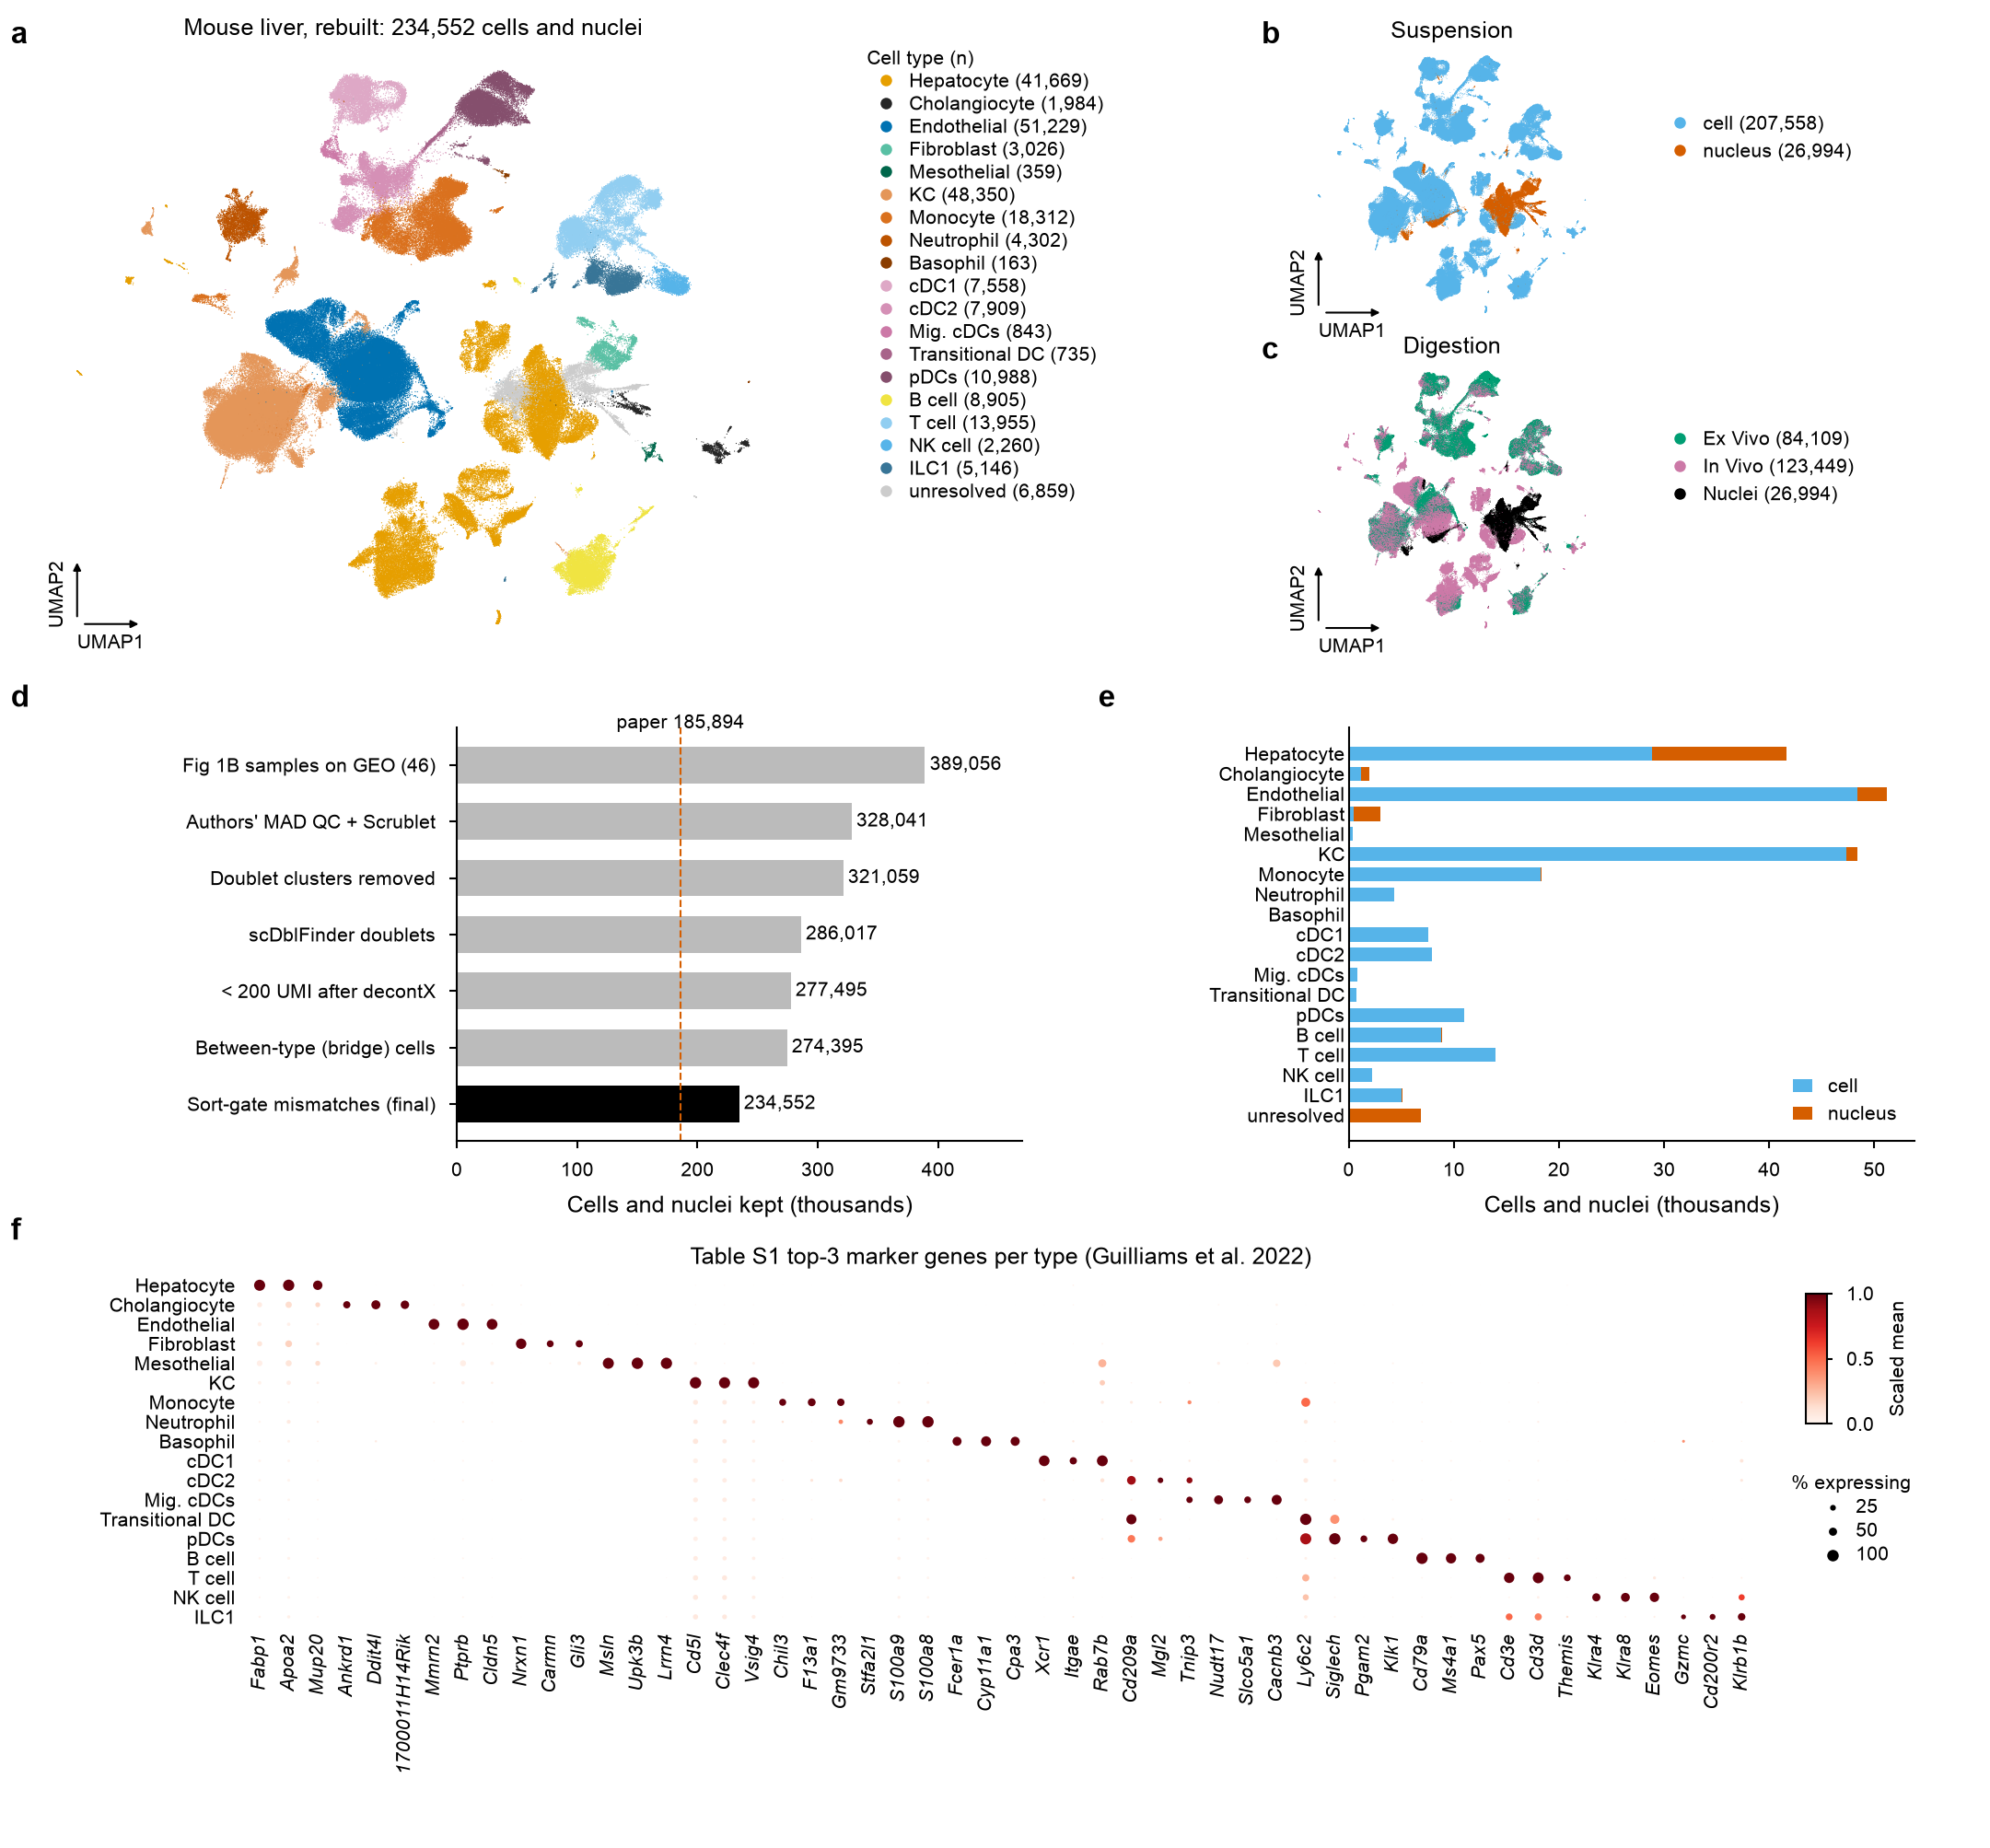

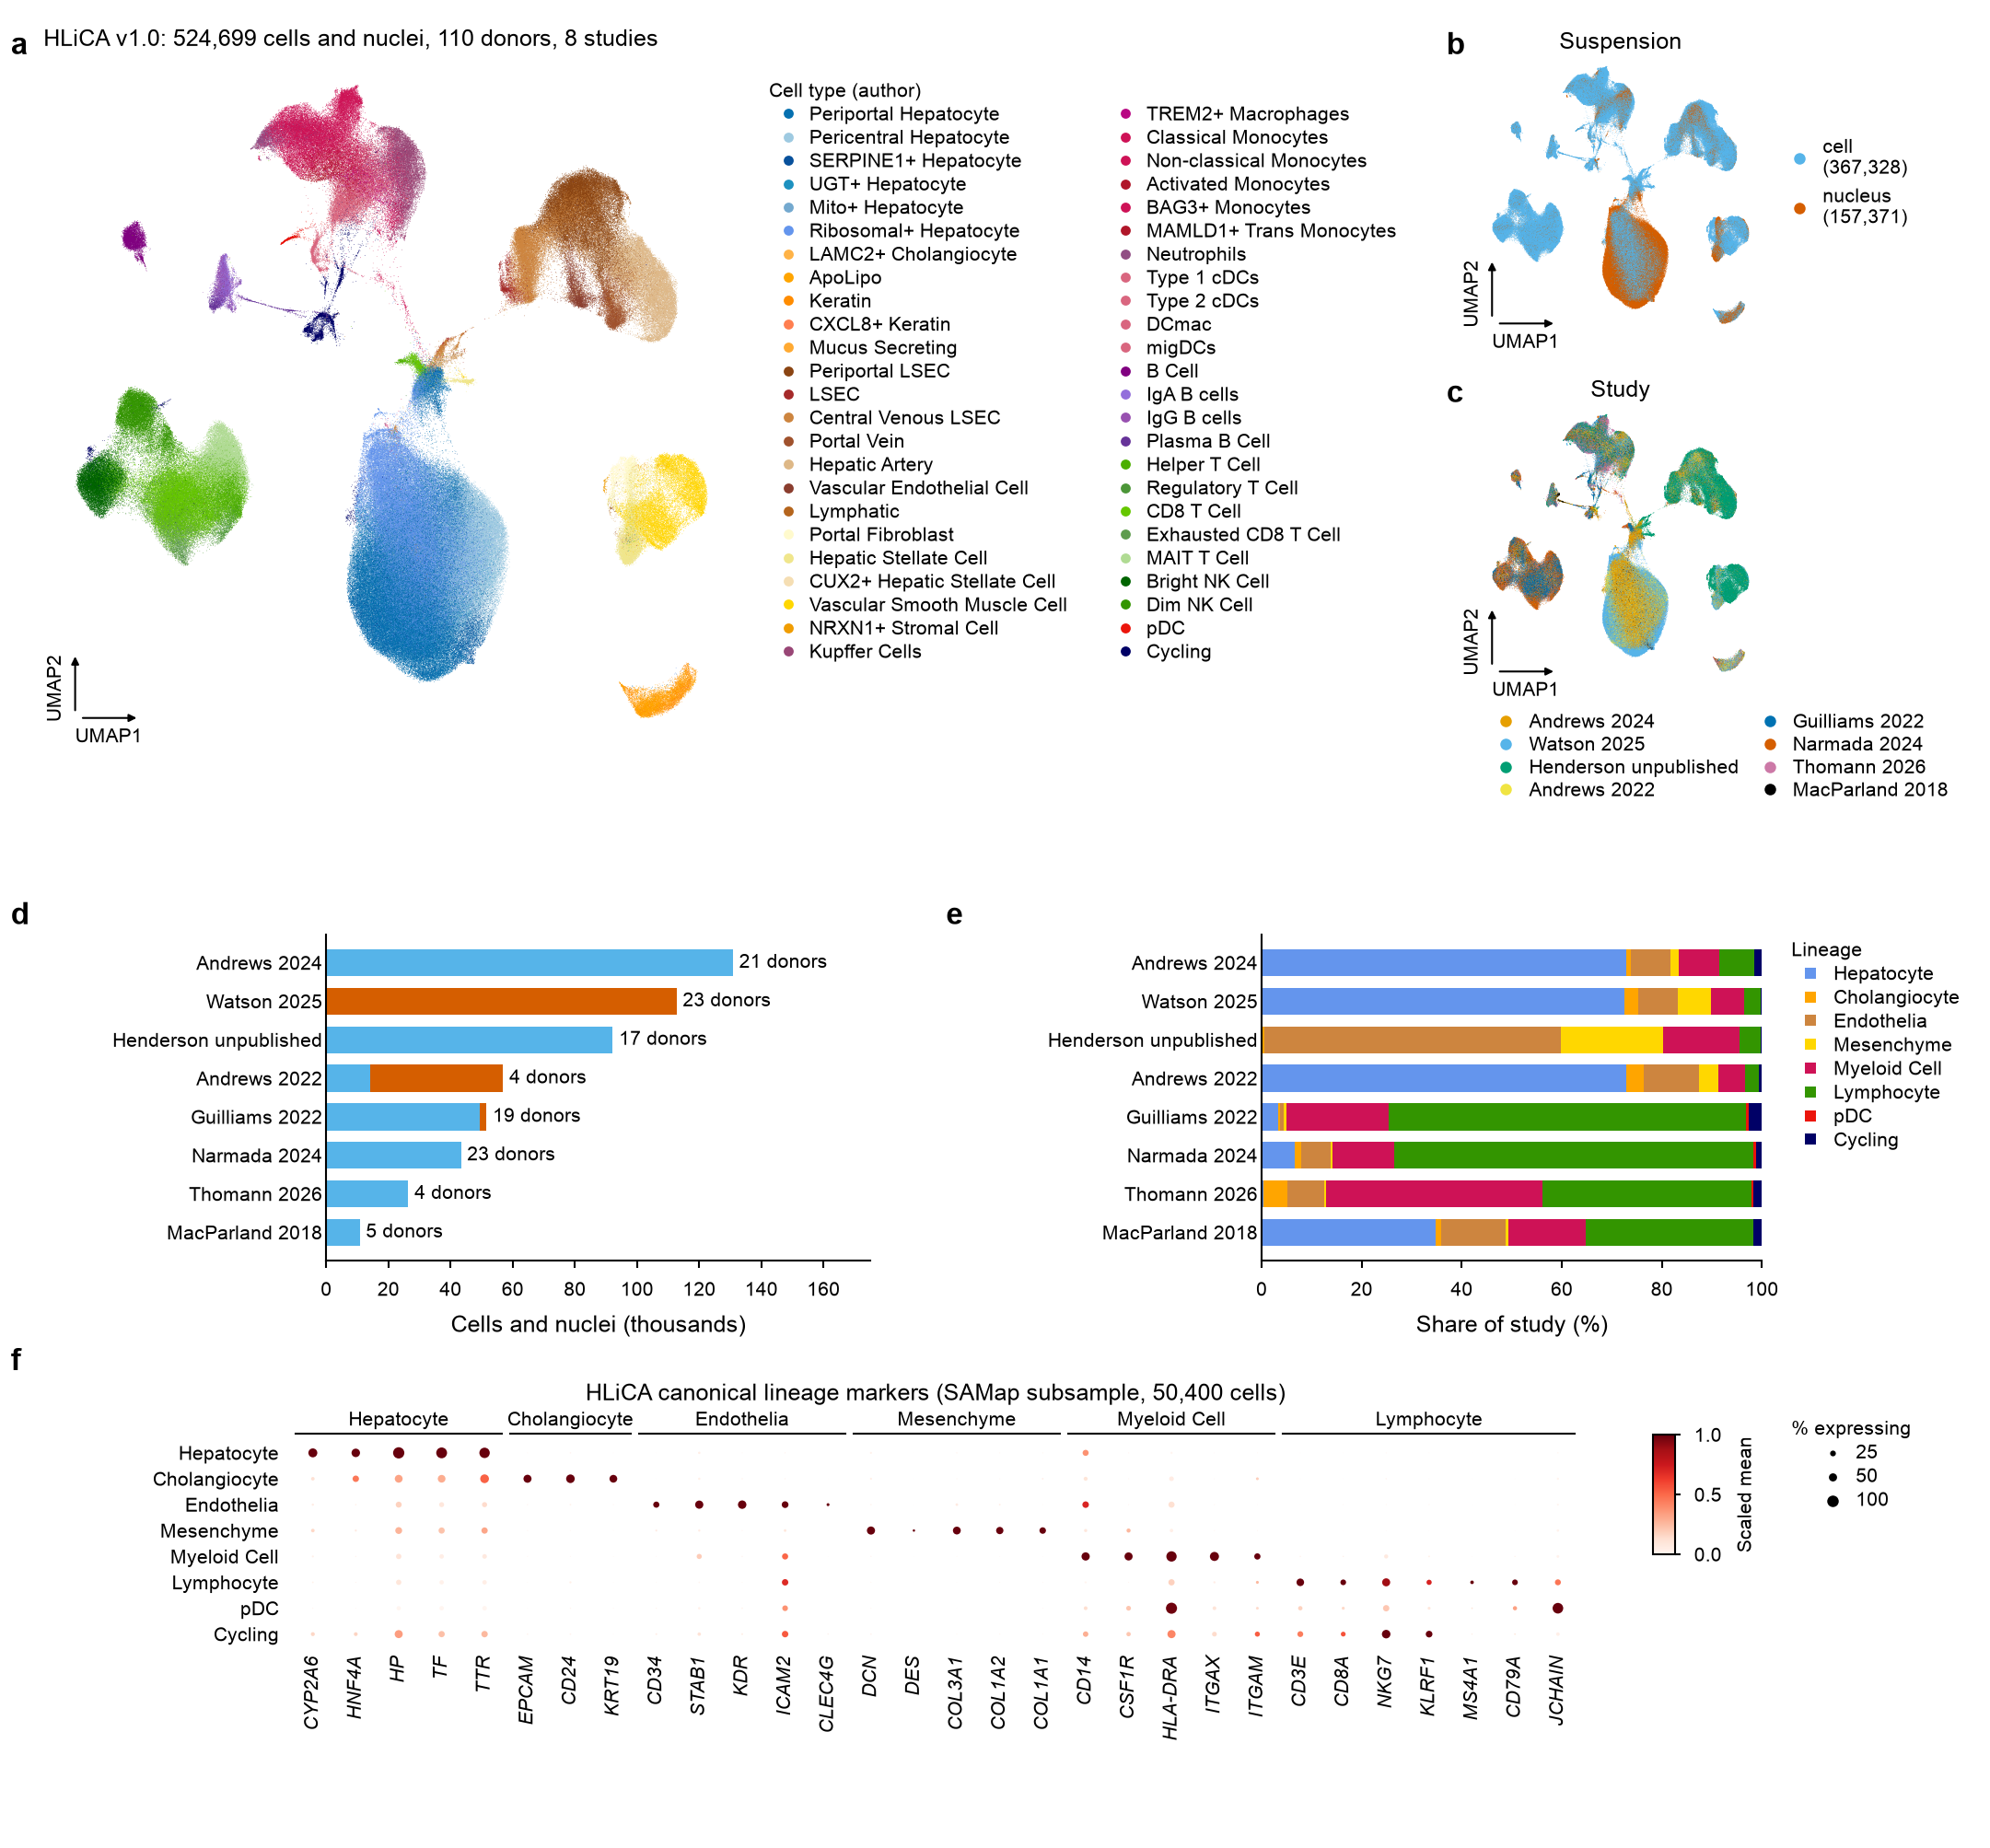

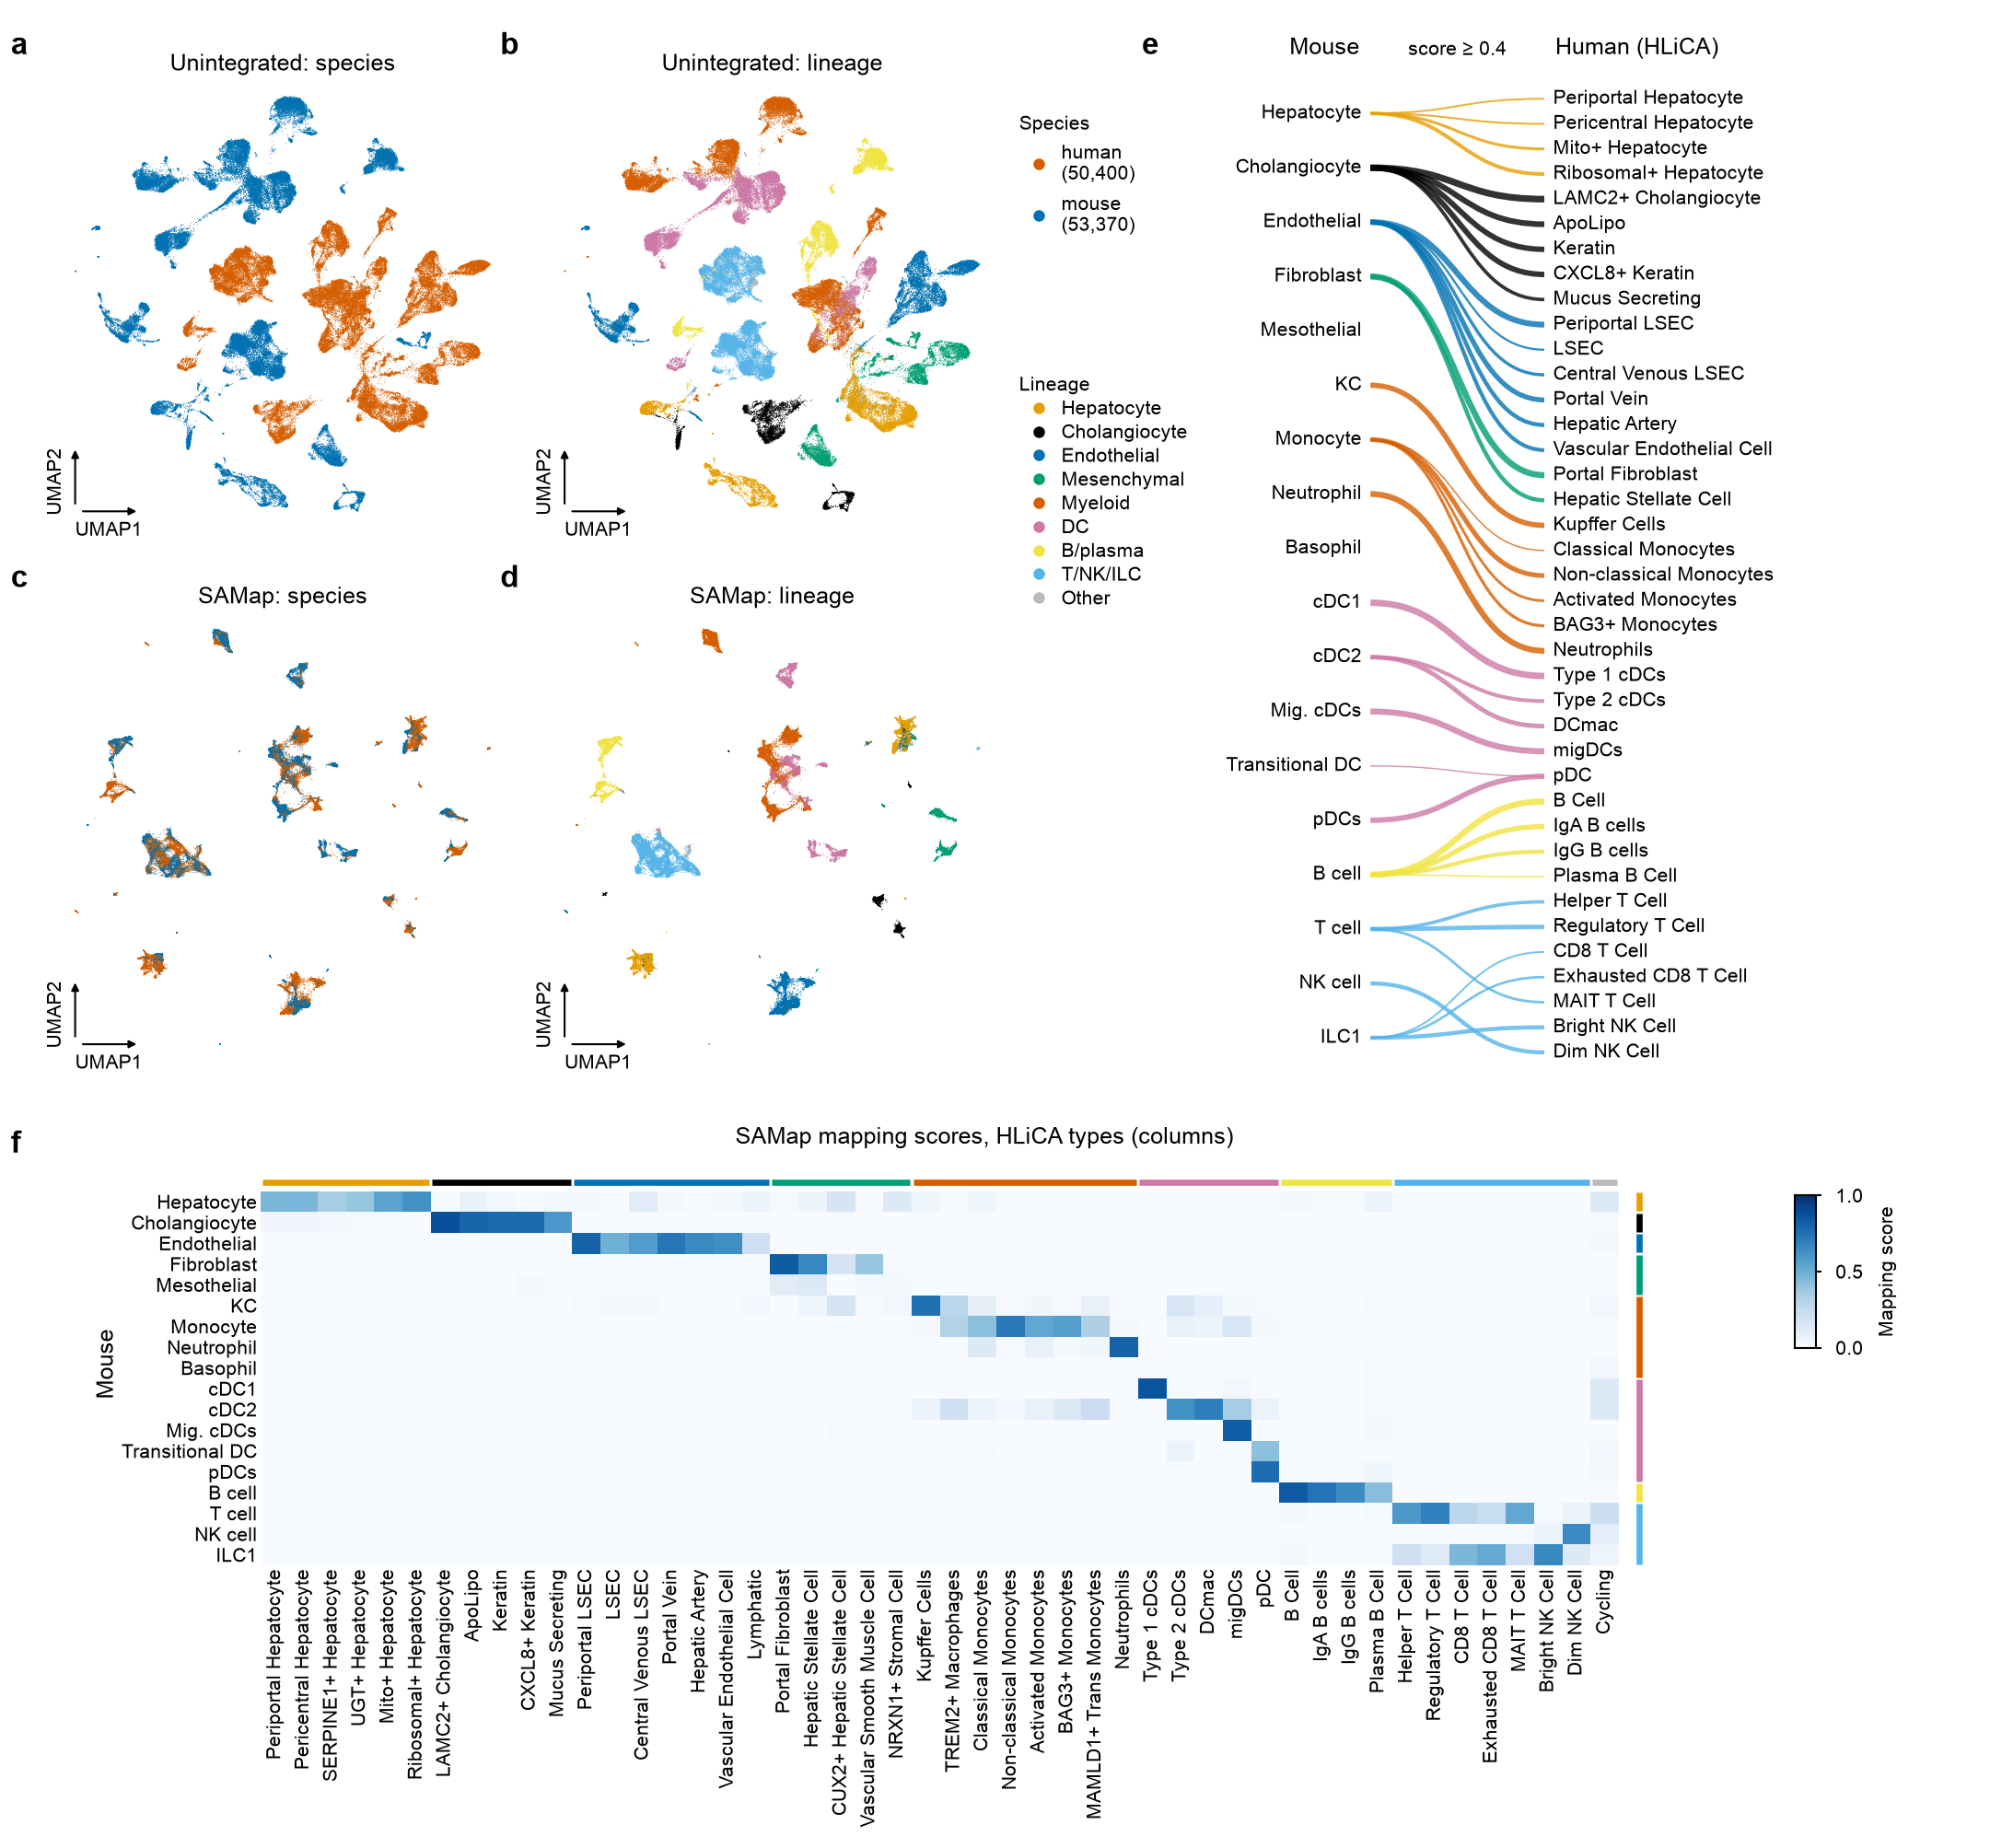

In [21]:
for f in ("fig1_mouse_atlas", "fig2_hlica", "fig3_samap"): show(f"figures/{f}.png", width=1000)